# 05 - Baseline Model

## Objective
Build an initial machine learning model using Simple Linear
Regression to predict appliance energy consumption.

Evaluate the model using standard regression metrics and
establish a baseline for future model experiments.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/processed/energydata_feature_engineered.csv")

df.head()

,date,Appliances,lights,T1,RH_1,T2,RH_2,T3,RH_3,T4,...,day,month,day_of_week,is_weekend,hour_sin,hour_cos,temp_diff_indoor_outdoor,humidity_diff_indoor_outdoor,avg_indoor_temp,avg_indoor_humidity
0,2016-01-11 17:00:00,60,30,19.89,47.596667,19.2,44.790000,19.79,44.730000,19.000000,...,11,1,0,0,-0.965926,-0.258819,13.290000,-44.403333,17.167407,50.910741
1,2016-01-11 17:10:00,60,30,19.89,46.693333,19.2,44.722500,19.79,44.790000,19.000000,...,11,1,0,0,-0.965926,-0.258819,13.406667,-45.306667,17.149630,50.827222
2,2016-01-11 17:20:00,50,30,19.89,46.300000,19.2,44.626667,19.79,44.933333,18.926667,...,11,1,0,0,-0.965926,-0.258819,13.523333,-45.700000,17.103704,50.628889
3,2016-01-11 17:30:00,50,40,19.89,46.066667,19.2,44.590000,19.79,45.000000,18.890000,...,11,1,0,0,-0.965926,-0.258819,13.640000,-45.933333,17.067037,50.574815
4,2016-01-11 17:40:00,60,40,19.89,46.333333,19.2,44.530000,19.79,45.000000,18.890000,...,11,1,0,0,-0.965926,-0.258819,13.756667,-45.666667,17.070741,50.732963


In [2]:
df.shape

(19735, 39)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19735 entries, 0 to 19734
Data columns (total 39 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   date                          19735 non-null  str    
 1   Appliances                    19735 non-null  int64  
 2   lights                        19735 non-null  int64  
 3   T1                            19735 non-null  float64
 4   RH_1                          19735 non-null  float64
 5   T2                            19735 non-null  float64
 6   RH_2                          19735 non-null  float64
 7   T3                            19735 non-null  float64
 8   RH_3                          19735 non-null  float64
 9   T4                            19735 non-null  float64
 10  RH_4                          19735 non-null  float64
 11  T5                            19735 non-null  float64
 12  RH_5                          19735 non-null  float64
 13  T6          

In [4]:
df.columns.tolist()

['date',
 'Appliances',
 'lights',
 'T1',
 'RH_1',
 'T2',
 'RH_2',
 'T3',
 'RH_3',
 'T4',
 'RH_4',
 'T5',
 'RH_5',
 'T6',
 'RH_6',
 'T7',
 'RH_7',
 'T8',
 'RH_8',
 'T9',
 'RH_9',
 'T_out',
 'Press_mm_hg',
 'RH_out',
 'Windspeed',
 'Visibility',
 'Tdewpoint',
 'rv1',
 'hour',
 'day',
 'month',
 'day_of_week',
 'is_weekend',
 'hour_sin',
 'hour_cos',
 'temp_diff_indoor_outdoor',
 'humidity_diff_indoor_outdoor',
 'avg_indoor_temp',
 'avg_indoor_humidity']

### Independent and Dependent Variables

- Independent Variable (X): `hour`
- Dependent Variable (y): `Appliances`

We will use the hour of the day to predict appliance energy consumption.

### Exploring the Feature

Before training the model, we will examine the distribution
of appliance consumption across different hours.

This helps us understand the relationship between our
selected feature and the target variable.

In [5]:
df[['hour', 'Appliances']].describe()

,hour,Appliances
count,19735.000000,19735.000000
mean,11.502002,97.694958
std,6.921953,102.524891
min,0.000000,10.000000
25%,6.000000,50.000000
50%,12.000000,60.000000
75%,17.000000,100.000000
max,23.000000,1080.000000


In [6]:
df.groupby('hour')['Appliances'].mean()

hour
0      52.785888
1      51.326034
2      49.075426
3      48.236010
4      49.355231
5      52.737226
6      57.712895
7      78.649635
8     106.143552
9     112.785888
10    125.377129
11    133.126521
12    123.637470
13    124.744526
14    108.284672
15    105.827251
16    119.902676
17    161.352657
18    190.364520
19    143.065693
20    126.982968
21     96.496350
22     69.148418
23     56.982968
Name: Appliances, dtype: float64

## 4. Visualizing the Relationship

We will create a scatter plot to examine the relationship
between the hour of the day and appliance energy consumption.

This will help us understand whether a linear model is
a reasonable starting point.

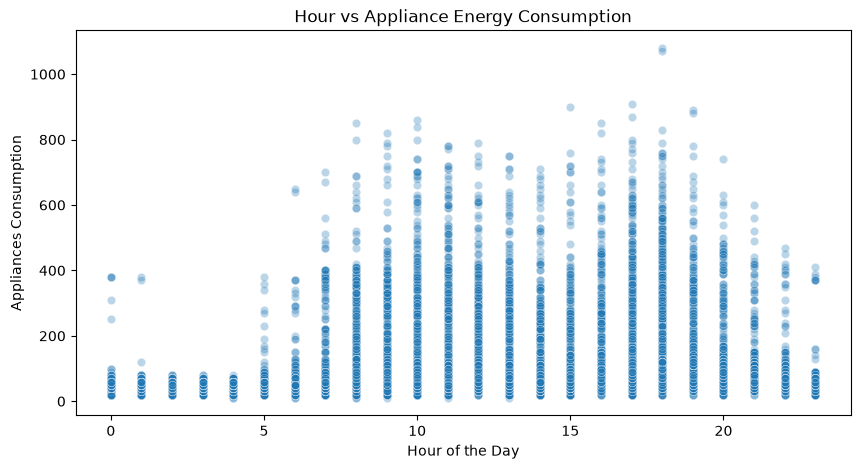

In [7]:
plt.figure(figsize=(10, 5))

sns.scatterplot(data=df, x='hour', y='Appliances', alpha=0.3)

plt.title('Hour vs Appliance Energy Consumption')
plt.xlabel('Hour of the Day')
plt.ylabel('Appliances Consumption')

plt.show()

## 5. Preparing Features and Target

We will separate our dataset into:

- X: Independent variable (`hour`)
- y: Dependent variable (`Appliances`)

For this initial baseline, we will use only one feature.

In [8]:
X = df[['hour']]
y = df['Appliances']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (19735, 1)
y shape: (19735,)


## 6. Splitting the Dataset

We will divide the dataset into 80% training data and 20%
testing data.

Since our dataset contains chronological observations,
we will preserve their original order by setting
`shuffle=False`.

This ensures that the model is trained on earlier
observations and evaluated on later observations.

In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    shuffle=False
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (15788, 1)
X_test: (3947, 1)
y_train: (15788,)
y_test: (3947,)


## 7. Training the Baseline Model

We will use Scikit-learn's LinearRegression algorithm
to train a Simple Linear Regression model.

### Mathematical Foundation

Simple Linear Regression represents the relationship
between an independent variable and a dependent variable
using a straight line.

**Regression Equation:**

$$
\hat{y} = b_0 + b_1x
$$

Where:

- $\hat{y}$ = Predicted target value
- $b_0$ = Intercept
- $b_1$ = Regression coefficient (slope)
- $x$ = Independent variable

**Our Learned Equation:**

$$
\hat{y} = 58.5989 + 3.429x
$$

The model learns the intercept and coefficient by
minimizing the sum of squared residuals.

**Objective Function:**

$$
\min_{b_0,b_1}
\sum_{i=1}^{n}
(y_i - \hat{y}_i)^2
$$

In [10]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[3.43]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hour']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,58.6
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [11]:
print("Intercept:", model.intercept_)
print("Coefficient:", model.coef_[0])

Intercept: 58.598882001683855
Coefficient: 3.42895228811762


## 8. Generating Predictions

We will use the trained Linear Regression model to predict
appliance energy consumption on the testing dataset.

These predictions will later be compared with the actual
values to evaluate model performance.

In [12]:
y_pred = model.predict(X_test)

print("First 10 predictions:")
print(y_pred[:10])

First 10 predictions:
[86.03050031 86.03050031 86.03050031 86.03050031 89.45945259 89.45945259
 89.45945259 89.45945259 89.45945259 89.45945259]


## 9. Comparing Actual and Predicted Values

We will compare the actual appliance consumption values
with the values predicted by our trained model.

This comparison helps us understand how closely the
model's predictions match the actual observations.

In [13]:
comparison = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred
})

comparison.head(10)

,Actual,Predicted
0,370,86.030500
1,590,86.030500
2,320,86.030500
3,310,86.030500
4,260,89.459453
5,190,89.459453
6,150,89.459453
7,130,89.459453
8,290,89.459453
9,490,89.459453


## 10. Evaluating Baseline Model Performance

We will evaluate our trained model using four regression
metrics:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- Root Mean Squared Error (RMSE)
- R² Score

These metrics will establish our initial baseline
performance for future model comparisons.

In [14]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 49.130347809372324
MSE: 8092.128978907561
RMSE: 89.95626147693979
R2 Score: 0.023634729017106282


## 11. Baseline Model Results

### Model
Simple Linear Regression

### Feature
- Independent variable: `hour`
- Target variable: `Appliances`

### Evaluation Metrics

| Metric | Value |
|---|---:|
| MAE | 49.13 |
| MSE | 8092.13 |
| RMSE | 89.96 |
| R² Score | 0.0236 |

### Observation

The baseline model demonstrates weak predictive performance.

The R² score indicates that the model explains only
approximately 2.36% of the variation in appliance
energy consumption on the test dataset.

Using only the hour of the day is insufficient to
capture the complexity and variability of appliance
energy consumption.

This baseline will serve as a reference for evaluating
future machine learning models.

## 12. Residual Analysis

Residual analysis helps us understand where and how
our model makes prediction errors.

A residual is calculated as:

$$
e_i = y_i - \hat{y}_i
$$

Positive residuals indicate underprediction, while
negative residuals indicate overprediction.

We will visualize residuals to identify patterns
and understand the limitations of our model.

In [15]:
residuals = y_test - y_pred

print("First 10 residuals:")
print(residuals.head(10))

First 10 residuals:
15788    283.969500
15789    503.969500
15790    233.969500
15791    223.969500
15792    170.540547
15793    100.540547
15794     60.540547
15795     40.540547
15796    200.540547
15797    400.540547
Name: Appliances, dtype: float64


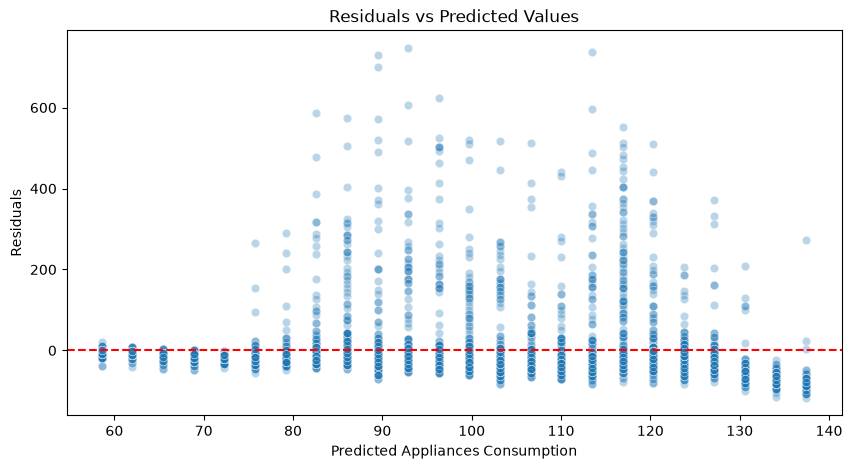

In [16]:
plt.figure(figsize=(10, 5))

sns.scatterplot(x=y_pred, y=residuals, alpha=0.3)

plt.axhline(y=0, color='red', linestyle='--')

plt.title('Residuals vs Predicted Values')
plt.xlabel('Predicted Appliances Consumption')
plt.ylabel('Residuals')

plt.show()

## 13. Baseline Model Conclusion

We trained a Simple Linear Regression model using
`hour` as the only independent variable to predict
`Appliances` consumption.

### Key Findings

- MAE: 49.13
- MSE: 8092.13
- RMSE: 89.96
- R² Score: 0.0236

### Residual Analysis

The residual plot revealed:

- Large positive and negative prediction errors.
- Uneven residual distribution.
- Visible patterns instead of random scatter.
- Repeated prediction values due to using a single feature.

### Conclusion

The Simple Linear Regression model provides a weak
baseline for predicting appliance energy consumption.

Using only the hour of the day is insufficient to
capture the complexity and variability of appliance
consumption.

This model will serve as a reference point for
evaluating more advanced regression approaches
in future experiments.